# 퍼널 분석
- 주문 생성 → 결제 승인 → 배송 시작 → 배송 완료 → 재구매

In [1]:
!pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------------------------------- -------- 7.3/9.3 MB 37.8 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 26.4 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 28.5 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ------------------------------- -------- 5.8/7.2 MB 29.3 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 23.5 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   --

In [2]:
!pip install seaborn

In [3]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] ='Malgun Gothic'
plt.rcParams['axes.unicode_minus'] =False

conn = sqlite3.connect('../ecommerce.db')
os.makedirs('../output', exist_ok=True)

def query(sql):
    return pd.read_sql(sql, conn)

START_DATE    = '2017-01-01'
END_DATE      = '2018-08-31'
SNAPSHOT_DATE = '2018-09-01'

## 1. 주문 완료율 퍼널
1. 주문 상태 퍼널

In [13]:
test = query(f"""
    SELECT * FROM orders
""")

display(test)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00


In [18]:
# 전체 주문 데이터 가져오기
orders_df = query(f"""
    SELECT * FROM orders
    WHERE order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
""")

# 주문 단계
# 퍼널 분석 대상: 정상 처리된 주문만
# canceled, unavailable 제외
base_df = orders_df[~orders_df['order_status'].isin(['canceled', 'unavailable'])]

order_created    = len(base_df)
payment_approved = base_df['order_approved_at'].notna().sum()
shipped          = base_df['order_delivered_carrier_date'].notna().sum()
delivered        = (base_df['order_status'] == 'delivered').sum()

funnel_data = {
    'Order Created' : order_created,
    'Payment Approved' : payment_approved,
    'Shipped' : shipped,
    'Delivered' : delivered
}

print("📊 주문 퍼널")
for stage, value in funnel_data.items():
    rate = value / order_created * 100
    print(f"{stage:20s}: {value:,}건 ({rate:.1f}%)")

📊 주문 퍼널
Order Created       : 97,910건 (100.0%)
Payment Approved    : 97,891건 (100.0%)
Shipped             : 97,306건 (99.4%)
Delivered           : 96,211건 (98.3%)


[주문 퍼널 분석 결론]
- 전체 주문 완료율 98.3%
- 최대 미완료 구간: 배송시작 → 배송완료 (1,095건, 1.1%)  
 → 배송 분실, 주소 오류 등 배송 품질 이슈 예상

2. 퍼널 시각화

              stage  count   rate  drop_off
0     Order Created  97910  100.0         0
1  Payment Approved  97891  100.0        19
2           Shipped  97306   99.4       585
3         Delivered  96211   98.3      1095


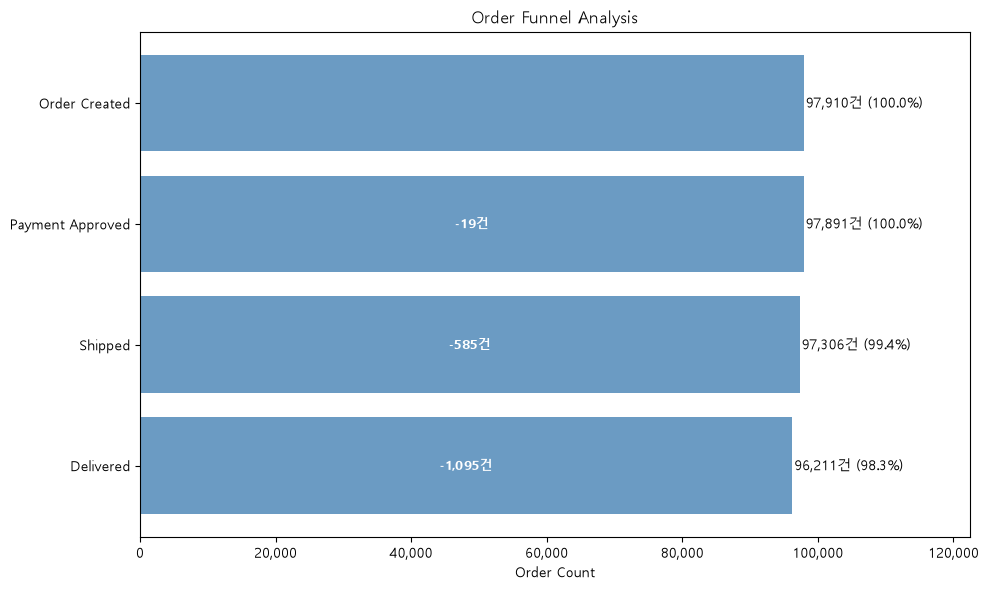

In [19]:
funnel_df = pd.DataFrame({
    'stage' : list(funnel_data.keys()),
    'count' : list(funnel_data.values())
})
funnel_df['rate'] = (funnel_df['count'] / funnel_df['count'][0] * 100).round(1)
funnel_df['drop_off'] = funnel_df['count'].diff().fillna(0).abs().astype(int)

print(funnel_df)

# 시각화
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(funnel_df['stage'][::-1],
               funnel_df['count'][::-1],
               color='steelblue', alpha=0.8)

for bar, (_, row) in zip(bars, funnel_df[::-1].iterrows()):
    # 오른쪽: 건수 + 완료율
    ax.text(bar.get_width() + 300,
            bar.get_y() + bar.get_height() / 2,
            f"{row['count']:,}건 ({row['rate']}%)",
            va='center', fontsize=10)
    # 안쪽: 이탈 수
    if row['drop_off'] > 0:
        ax.text(bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f"-{row['drop_off']:,}건",
                va='center', ha='center',
                color='white', fontsize=9, fontweight='bold')

ax.set_title('Order Funnel Analysis')
ax.set_xlabel('Order Count')
ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_xlim(0, max(funnel_df['count']) * 1.25)
plt.tight_layout()
plt.savefig('../output/order_funnel.png', dpi=150)
plt.show()

3. 결제 수단별 완료율

,payment_type,total_orders,delivered_orders,completion_rate
0,boleto,19479,19140,98.3
1,credit_card,75676,74376,98.3
2,debit_card,1514,1484,98.0
3,voucher,5590,5473,97.9


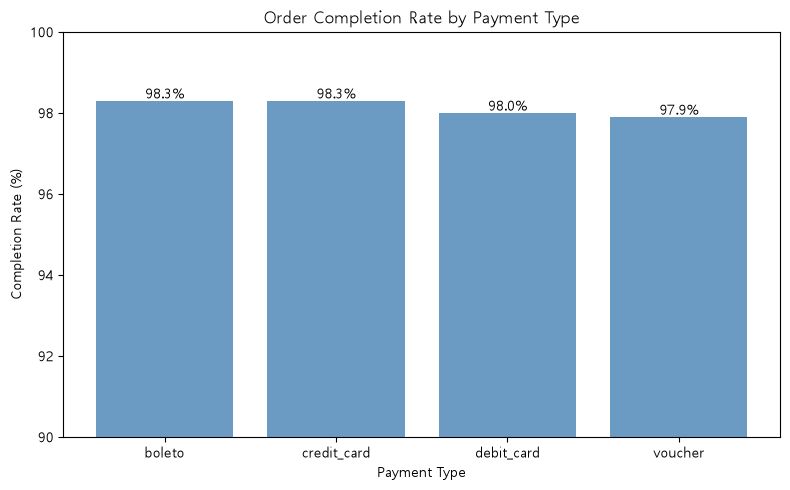

In [26]:
# payments 테이블 가져오기
payments_df = query(f"""
    SELECT order_id, payment_type
    FROM payments
    WHERE order_id IN (
        SELECT order_id FROM orders
        WHERE order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
        )
""")

payment_funnel = (orders_df[~orders_df['order_status'].isin(['canceled', 'unavailable'])]
                    .merge(payments_df, on='order_id')
                    .groupby('payment_type')
                    .agg(
                        total_orders = ('order_id', 'count'),
                        delivered_orders = ('order_status', lambda x: (x == 'delivered').sum())
                    )
                    .reset_index())

payment_funnel['completion_rate'] = (payment_funnel['delivered_orders'] / payment_funnel['total_orders'] * 100).round(1)

payment_funnel = payment_funnel.sort_values('completion_rate', ascending=False)
display(payment_funnel)

# 시각화
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(payment_funnel['payment_type'],
              payment_funnel['completion_rate'],
              color='steelblue', alpha=0.8)
ax.set_ylim(90, 100)
ax.set_title('Order Completion Rate by Payment Type')
ax.set_xlabel('Payment Type')
ax.set_ylabel('Completion Rate (%)')
for bar, rate in zip(bars, payment_funnel['completion_rate']):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f'{rate}%', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('../output/payment_completion.png', dpi=150)
plt.show()

[결제 수단별 완료율 결론]
- 모든 결제 수단 완료율 97.9~98.3% → 차이 0.4%p 이내
- 결제 수단은 주문 완료율에 영향 없음

4. 배송 소요일 분석

📦 배송 소요일 통계
count    96203.0
mean        12.1
std          9.5
min          0.0
25%          6.0
50%         10.0
75%         15.0
max        209.0
Name: delivery_days, dtype: float64


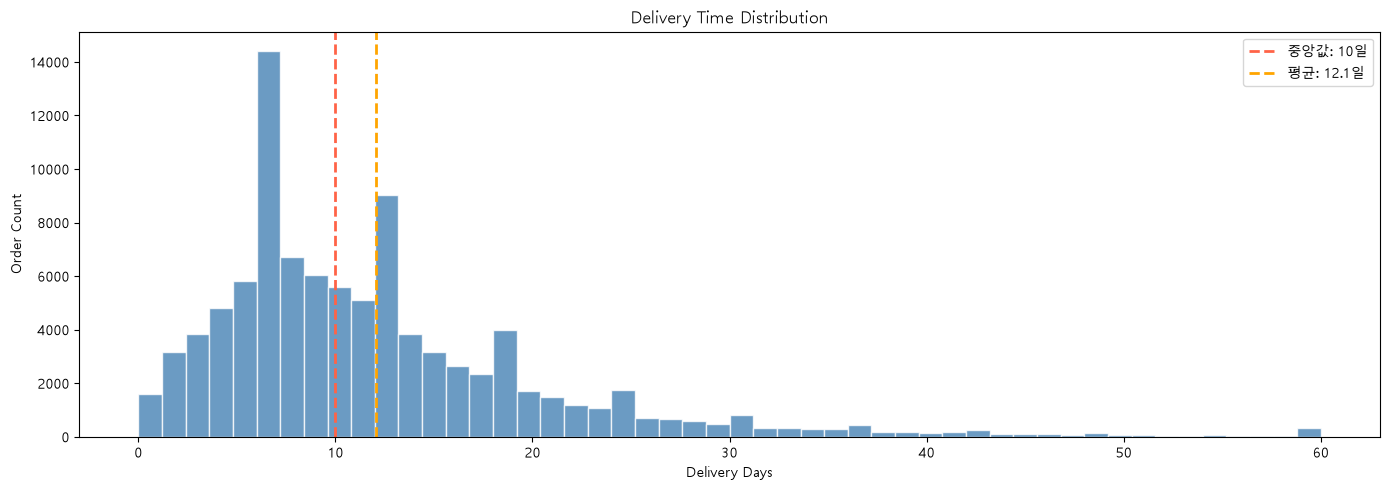

In [27]:
delivery_df = orders_df[
    (orders_df['order_status'] == 'delivered') &
    (orders_df['order_delivered_customer_date'].notna())
].copy()

# 날짜 컬럼 변환
delivery_df['order_purchase_timestamp'] = pd.to_datetime(
    delivery_df['order_purchase_timestamp'])
delivery_df['order_delivered_customer_date'] = pd.to_datetime(
    delivery_df['order_delivered_customer_date'])

# 배송 소요일 계산
delivery_df['delivery_days'] = (
    delivery_df['order_delivered_customer_date']
    - delivery_df['order_purchase_timestamp']
).dt.days

print("📦 배송 소요일 통계")
print(delivery_df['delivery_days'].describe().round(1))

# 시각화
fig, ax = plt.subplots(figsize=(14, 5))
ax.hist(delivery_df['delivery_days'].clip(upper=60),
        bins=50, color='steelblue', alpha=0.8, edgecolor='white')

median_days = delivery_df['delivery_days'].median()
mean_days   = delivery_df['delivery_days'].mean()

ax.axvline(median_days, color='tomato', linestyle='--', linewidth=2,
           label=f"중앙값: {median_days:.0f}일")
ax.axvline(mean_days, color='orange', linestyle='--', linewidth=2,
           label=f"평균: {mean_days:.1f}일")
ax.set_title('Delivery Time Distribution')
ax.set_xlabel('Delivery Days')
ax.set_ylabel('Order Count')
ax.legend()
plt.tight_layout()
plt.savefig('../output/delivery_time.png', dpi=150)
plt.show()

[배송 소요일 분석 결론]
- 중앙값 10일, 평균 12.1일
- 두 개의 봉우리: 6-7일(근거리), 10-13일(원거리)  
  → 브라질 국토 특성상 지역별 배송 기간 차이 큼
- 25% 고객이 15일 초과 배송 → 장거리 배송 개선 필요
- 최대 209일은 극단적 이상치 → 데이터 품질 이슈 가능성

5. 배송 소요일 vs 리뷰 점수

In [28]:
a = query(""" SELECT * FROM reviews """)
display(a)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53
...,...,...,...,...,...,...,...
99219,574ed12dd733e5fa530cfd4bbf39d7c9,2a8c23fee101d4d5662fa670396eb8da,5,NaN,NaN,2018-07-07 00:00:00,2018-07-14 17:18:30
99220,f3897127253a9592a73be9bdfdf4ed7a,22ec9f0669f784db00fa86d035cf8602,5,NaN,NaN,2017-12-09 00:00:00,2017-12-11 20:06:42
99221,b3de70c89b1510c4cd3d0649fd302472,55d4004744368f5571d1f590031933e4,5,NaN,"Excelente mochila, entrega super rápida. Super...",2018-03-22 00:00:00,2018-03-23 09:10:43
99222,1adeb9d84d72fe4e337617733eb85149,7725825d039fc1f0ceb7635e3f7d9206,4,NaN,NaN,2018-07-01 00:00:00,2018-07-02 12:59:13


,delivery_days,avg_review_score,order_count
1,1,4.50,1572
2,2,4.48,3161
3,3,4.43,3850
4,4,4.43,4829
5,5,4.39,5800
6,6,4.38,6806
7,7,4.38,7601
8,8,4.35,6740
9,9,4.30,6024
10,10,4.31,5602


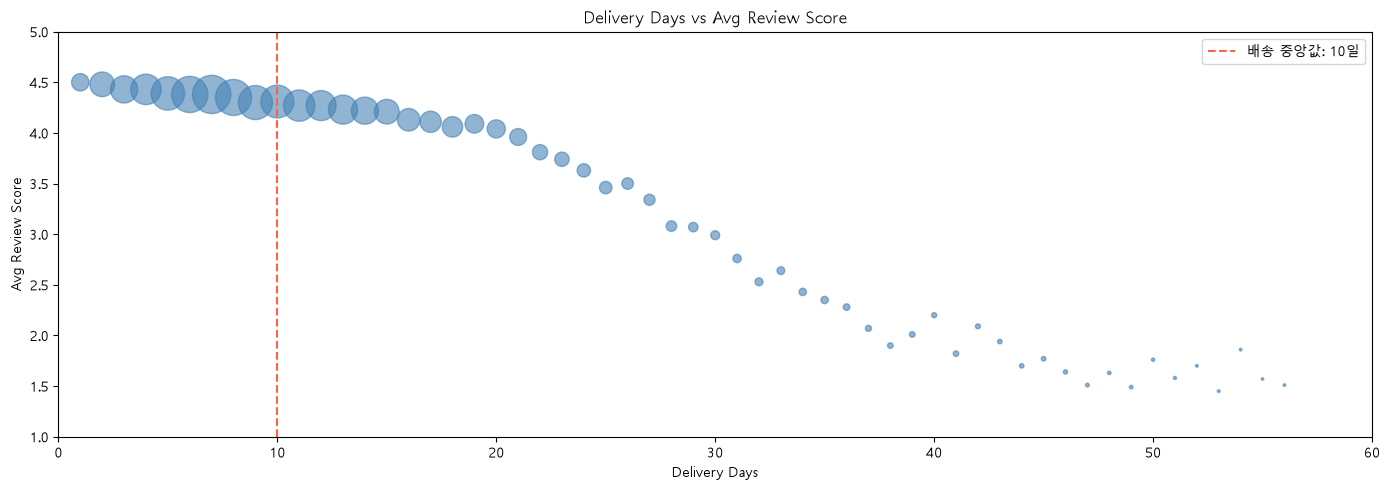

In [35]:
reviews_df = query("""
    SELECT order_id, review_score
    FROM reviews
""")

# delivery랑 merge
delivery_review = (delivery_df
                   .merge(reviews_df, on='order_id')
                   .groupby('delivery_days')
                   .agg(
                       avg_review_score=('review_score', 'mean'),
                       order_count=('order_id', 'count')
                   )
                   .reset_index()
                   .round({'avg_review_score': 2})
                   .query("order_count >= 30"))

display(delivery_review.head(10))

# 시각화
fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(delivery_review['delivery_days'],
           delivery_review['avg_review_score'],
           s=delivery_review['order_count'] / 10,
           color='steelblue', alpha=0.6)
ax.axvline(delivery_df['delivery_days'].median(),
           color='tomato', linestyle='--', linewidth=1.5,
           label=f"배송 중앙값: {delivery_df['delivery_days'].median():.0f}일")
ax.set_title('Delivery Days vs Avg Review Score')
ax.set_xlabel('Delivery Days')
ax.set_ylabel('Avg Review Score')
ax.set_xlim(0, 60)
ax.set_ylim(1, 5)
ax.legend()
plt.tight_layout()
plt.savefig('../output/delivery_vs_review.png', dpi=150)
plt.show()

[배송 소요일 vs 리뷰 점수 결론]
- 배송일이 길어질수록 리뷰 점수 명확하게 하락 (우하향)
- 임계점: 30일 초과 시 리뷰 점수 3점 이하 (불만족)
- 중앙값(10일) 기준 이내: 4.3점 이상 유지
- 분석 2 결과와 연계: 배송 지연 → 불만족 → 이탈 가능성

In [36]:
# 배송 지연 여부 분류 (중앙값 10일 기준)
delivery_df['is_delayed'] = delivery_df['delivery_days'] > 10

delayed_review = (delivery_df
                  .merge(reviews_df, on='order_id')
                  .groupby('is_delayed')['review_score']
                  .agg(['mean', 'count'])
                  .round(2))

delayed_review.index = ['정상 배송 (10일 이내)', '지연 배송 (10일 초과)']
print(delayed_review)

                mean  count
정상 배송 (10일 이내)  4.38  51998
지연 배송 (10일 초과)  3.89  44089


- 주문 완료율 98.3%, 결제 수단별 차이 없음 → 운영/결제 안정적
- 전체 주문의 45.8%가 10일 초과 배송 (지연)
- 지연 배송 리뷰 3.89점 vs 정상 배송 4.38점 → 0.49점 차이
- 30일 초과 시 리뷰 3점 이하로 급락 → 30일을 배송 SLA 기준으로 제안
- 배송 속도 개선이 고객 만족도 향상의 핵심 과제

6. 리뷰 감성 분석

In [38]:
!pip install transformers torch

   ---------------------------------------- 0.0/12.3 MB ? eta -:--:--
   ---------------------- ----------------- 6.8/12.3 MB 32.3 MB/s eta 0:00:01
   ---------------------------------------- 12.3/12.3 MB 29.6 MB/s  0:00:00
   ---------------------------------------- 0.0/798.3 kB ? eta -:--:--
   ---------------------------------------- 798.3/798.3 kB 17.3 MB/s  0:00:00
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 4.0/4.0 MB 26.7 MB/s  0:00:00
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 2.9/2.9 MB 42.0 MB/s  0:00:00
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   -- ------------------------------------- 7.3/124.1 MB 41.2 MB/s eta 0:00:03
   ---- ----------------------------------- 14.4/124.1 MB 34.8 MB/s eta 0:00:04
   ------ --------------------------------- 20.4/124.1 MB 33.1 MB/s eta 0:00:04
   --------- ------------------